# E238 — Can a stronger SSL objective acquire new semantics?

**complete** · Eight paired walks and all gate reads complete

2026-11-23T15:43:38+01:00 Stockholm time · ETA **—**

Eight fresh capture-disjoint walks follow A→B→A with 192 batch-two updates per regime. Within each walk, all adapting DINO arms share an incoming-only first A and its resulting model and optimizer state. The MAE arm also uses incoming-only first A. Reference preservation starts with replay at B. Each walk is one independent trajectory replicate with a common crop RNG across adapting DINO policies. All four semantic tasks contribute equally.

DINO starts from the archived pretrained ViT-B/16 teacher, student, heads and primed center. Batch-two training uses two 224 px global crops and four 96 px local crops. Native cosine EMA, optimizer groups and temperatures follow the archived recipe. The teacher is the prespecified primary representation. Student probes at regime boundaries are reported separately. Both replay arms use the same 64-image past-only reservoir and replace 25% of image exposures after first A. The preservation arm adds a fixed weight-one cosine penalty against the immutable initial DINO teacher on replay images.

The common external corpus uses the same photos and fit/query IDs for DINO and MAE. DINO receives 224 px crops and MAE receives its native 64 px inputs. Each readout refits the same linear-probe protocol. Independent raw A/B holdouts anchor the corresponding labeled panels. Each query class has at least 30 examples per walk and side. The walk bootstrap conditions on this fixed evaluation corpus. Labels are used only for evaluation.

The gate requires at least **+0.5 pp** on B at its exit relative to both pre-B and frozen DINO, with positive paired walk-clustered 95% intervals. At least two tasks must improve, and the aggregate must stay positive after excluding the largest task gain for each contrast.


## Gate decisions

8 paired walks included.

| Policy | B exit vs pre-B (pp) | B exit vs frozen DINO (pp) | A at return vs B exit (pp) | B vs frozen, strongest task removed (pp) | Gate |
| --- | --- | --- | --- | --- | --- |
| Frozen DINO | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | +0.000 [+0.000, +0.000] | — |
| Incoming DINO | -0.412 [-1.172, +0.262] | -1.322 [-2.181, -0.556] | +0.074 [-0.050, +0.192] | -1.948 [-2.641, -1.390] | missed |
| DINO + 25% replay | -0.126 [-0.424, +0.305] | -1.036 [-1.418, -0.622] | +0.128 [-0.091, +0.366] | -1.891 [-2.475, -1.400] | missed |
| DINO + 25% replay + preservation | -0.305 [-0.988, +0.360] | -1.216 [-1.753, -0.687] | +0.055 [-0.304, +0.314] | -2.131 [-2.633, -1.621] | missed |

## Absolute comparison with MAE

| Policy | A before B (%) | B at B exit (%) | A at return (%) | B at return (%) | Training time/walk (min) |
| --- | --- | --- | --- | --- | --- |
| Frozen DINO | 58.41 | 63.44 | 58.41 | 63.44 | 0.00 |
| Incoming DINO | 59.67 | 62.11 | 59.84 | 62.12 | 1.99 |
| DINO + 25% replay | 59.67 | 62.40 | 59.82 | 62.29 | 2.01 |
| DINO + 25% replay + preservation | 59.67 | 62.22 | 59.88 | 62.12 | 2.20 |
| MAE + 25% replay | 47.76 | 51.28 | 47.98 | 51.54 | 0.10 |

## B over pre-B

| DINO policy | scene | weather | traffic light | pedestrian | Removed task | Without strongest (pp) |
| --- | --- | --- | --- | --- | --- | --- |
| Incoming DINO | -1.410 [-2.321, -0.401] | -0.694 [-2.361, +0.556] | +0.092 [-0.958, +1.023] | +0.365 [-0.260, +1.126] | pedestrian | -0.671 [-1.549, +0.060] |
| DINO + 25% replay | -1.077 [-2.218, -0.050] | +0.278 [-0.833, +1.250] | +0.010 [-0.857, +0.829] | +0.286 [-0.320, +0.986] | pedestrian | -0.263 [-0.607, +0.164] |
| DINO + 25% replay + preservation | -1.700 [-2.900, -0.520] | +0.278 [-0.833, +1.528] | -0.398 [-1.339, +0.524] | +0.599 [+0.086, +1.198] | pedestrian | -0.607 [-1.442, +0.190] |

## B over frozen DINO

| DINO policy | scene | weather | traffic light | pedestrian | Removed task | Without strongest (pp) |
| --- | --- | --- | --- | --- | --- | --- |
| Incoming DINO | -3.108 [-3.934, -2.331] | +0.556 [-1.528, +2.361] | -1.086 [-1.989, -0.267] | -1.650 [-2.867, -0.634] | weather | -1.948 [-2.641, -1.390] |
| DINO + 25% replay | -2.775 [-3.567, -1.928] | +1.528 [+0.278, +2.917] | -1.169 [-2.137, -0.192] | -1.730 [-2.829, -0.750] | weather | -1.891 [-2.475, -1.400] |
| DINO + 25% replay + preservation | -3.398 [-3.964, -2.794] | +1.528 [+0.139, +2.778] | -1.577 [-2.416, -0.711] | -1.417 [-2.453, -0.309] | weather | -2.131 [-2.633, -1.621] |

## A return retention

| DINO policy | scene | weather | traffic light | pedestrian | Removed task | Without strongest (pp) |
| --- | --- | --- | --- | --- | --- | --- |
| Incoming DINO | +0.220 [-0.346, +0.823] | -0.379 [-0.864, +0.108] | +0.298 [-0.130, +0.707] | +0.158 [-0.241, +0.516] | traffic light | -0.001 [-0.183, +0.179] |
| DINO + 25% replay | +0.014 [-0.231, +0.258] | +0.173 [-0.278, +0.623] | +0.205 [-0.037, +0.410] | +0.121 [-0.437, +0.599] | traffic light | +0.102 [-0.153, +0.373] |
| DINO + 25% replay + preservation | +0.067 [-0.216, +0.417] | -0.139 [-0.417, +0.000] | +0.447 [+0.223, +0.652] | -0.155 [-0.878, +0.331] | traffic light | -0.075 [-0.507, +0.235] |

## Student readouts

| DINO policy | Update | A balanced accuracy (%) | B balanced accuracy (%) |
| --- | --- | --- | --- |
| Incoming DINO | 192 | 59.89 | 61.83 |
| Incoming DINO | 384 | 59.89 | 62.11 |
| Incoming DINO | 576 | 59.94 | 61.66 |
| DINO + 25% replay | 192 | 59.89 | 61.83 |
| DINO + 25% replay | 384 | 59.95 | 62.36 |
| DINO + 25% replay | 576 | 59.86 | 61.82 |
| DINO + 25% replay + preservation | 192 | 59.89 | 61.83 |
| DINO + 25% replay + preservation | 384 | 59.90 | 62.31 |
| DINO + 25% replay + preservation | 576 | 59.81 | 62.43 |

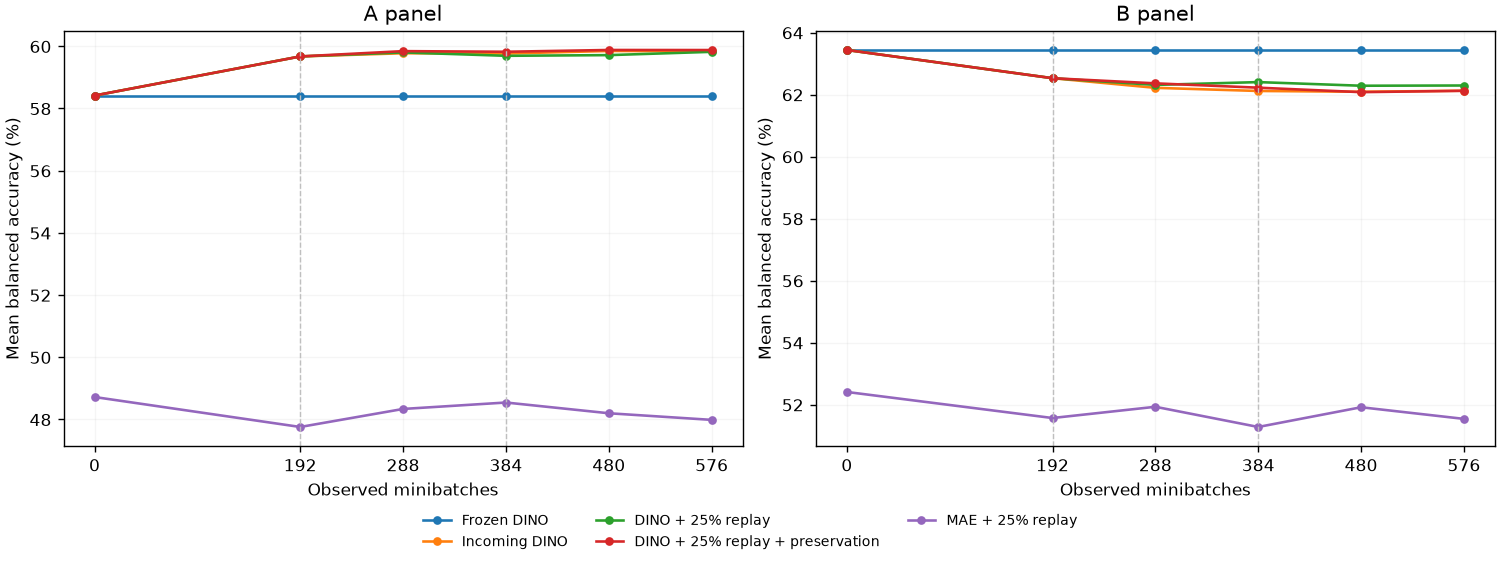